# 03 | Validation

Checks, with charts, that the generated data shows the patterns that were built into the model. Each chart starts with **what is expected**.

## Setup

In [1]:
import sys
from pathlib import Path

# Make the src/ folder importable when running from the notebooks/ folder
sys.path.append(str(Path.cwd().parent))

import numpy as np
import pandas as pd

from src.config import *
from src.utils import *
import matplotlib.pyplot as plt

dim_store = load_table("dim_store")
dim_product = load_table("dim_product")
dim_date = load_table("dim_date")
dim_promotion = load_table("dim_promotion")
fact_sales = load_table("fact_sales")

sales = (
    fact_sales
    .merge(dim_store[["store_id", "country", "store_type", "location_profile"]], on="store_id")
    .merge(dim_product[["product_id", "product_name", "category"]], on="product_id")
)
sales["month"] = sales["date"].dt.to_period("M").dt.to_timestamp()
print(f"{len(sales):,} rows")

1,504,031 rows


## 1. Growth and number of stores
**Expected:** revenue grows over time, with a strong yearly cycle; the number of open stores grows, especially from 2022 with the expansion to Spain, and drops slightly in 2024 with two closures.

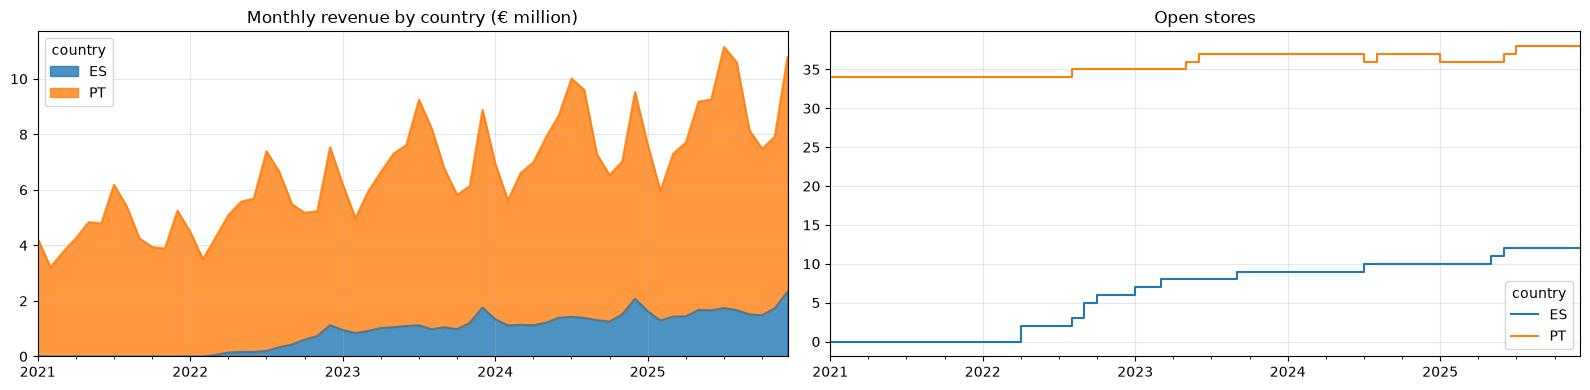

In [2]:
monthly = sales.groupby(["month", "country"])["revenue"].sum().unstack(fill_value=0)

open_stores = pd.DataFrame({
    month: ((dim_store["opening_date"] <= month)
            & (dim_store["closing_date"].isna() | (dim_store["closing_date"] >= month))).groupby(dim_store["country"]).sum()
    for month in monthly.index
}).T

fig, axes = plt.subplots(1, 2, figsize=(16, 4))
(monthly / 1e6).plot.area(ax=axes[0], alpha=0.8)
axes[0].set_title("Monthly revenue by country (€ million)")
open_stores.plot(ax=axes[1], drawstyle="steps-post")
axes[1].set_title("Open stores")
for ax in axes:
    ax.grid(alpha=0.3)
    ax.set_xlabel("")
plt.tight_layout()

In [3]:
yearly = sales.groupby(sales["date"].dt.year).agg(revenue=("revenue", "sum"), cost=("cost", "sum"), units=("quantity", "sum"))
yearly["margin_%"] = (100 * (yearly["revenue"] - yearly["cost"]) / yearly["revenue"]).round(1)
yearly["growth_%"] = (100 * yearly["revenue"].pct_change()).round(1)
yearly.style.format({"revenue": "€{:,.0f}", "cost": "€{:,.0f}", "units": "{:,.0f}"})

,revenue,cost,units,margin_%,growth_%
date,,,,,
2021,"€54,039,295","€30,830,586","1,291,713",42.900000,nan
2022,"€66,115,926","€37,815,115","1,448,815",42.800000,22.300000
2023,"€83,751,599","€47,879,819","1,691,236",42.800000,26.700000
2024,"€92,737,196","€53,103,046","1,802,376",42.700000,10.700000
2025,"€103,122,866","€59,052,981","1,948,651",42.700000,11.200000


## 2. Seasonality by category
**Expected:** Beach & Water peaks in July and August, Snow & Winter in December and January, Fitness in January and September, Running in January.

Index 100 = average month of the category.

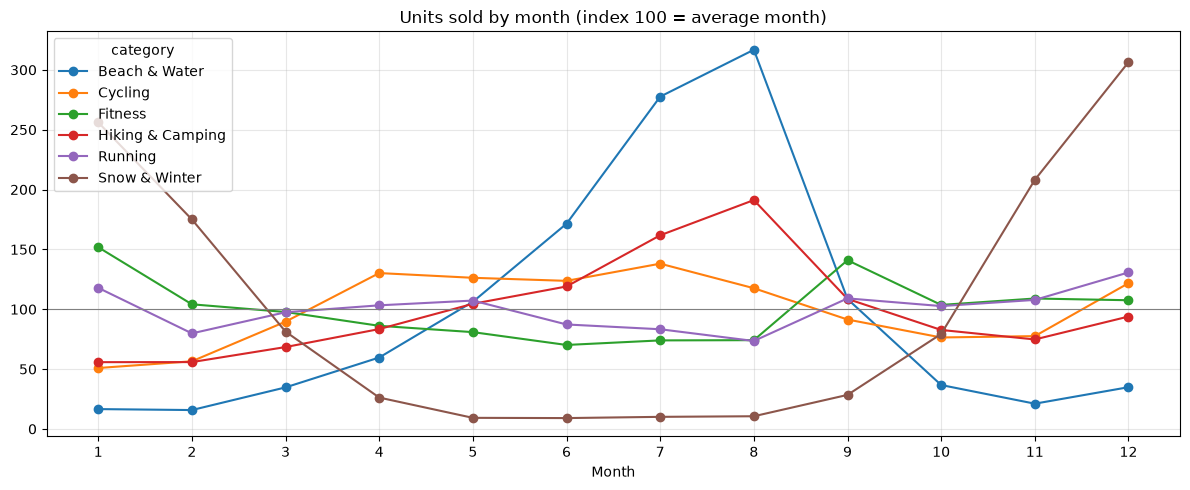

In [4]:
by_month = sales.groupby([sales["date"].dt.month, "category"])["quantity"].sum().unstack()
index = 100 * by_month / by_month.mean()

fig, ax = plt.subplots(figsize=(12, 5))
index.plot(ax=ax, marker="o")
ax.axhline(100, color="grey", linewidth=0.8)
ax.set_xticks(range(1, 13))
ax.set_xlabel("Month")
ax.set_title("Units sold by month (index 100 = average month)")
ax.grid(alpha=0.3)
plt.tight_layout()

## 3. Weekday profile
**Expected:** Saturday is the strongest day for every store type; street stores have no sales on Sundays.

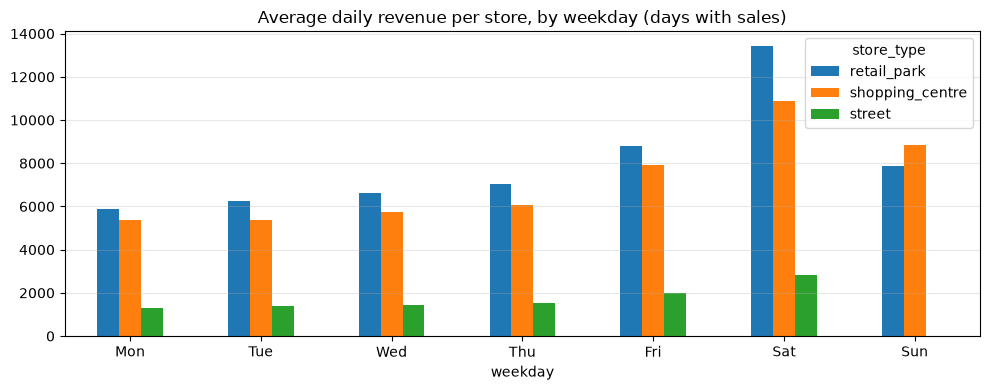

In [5]:
daily_store = sales.groupby(["date", "store_id", "store_type"])["revenue"].sum().reset_index()
daily_store["weekday"] = daily_store["date"].dt.day_name().str[:3]
weekday_order = ["Mon", "Tue", "Wed", "Thu", "Fri", "Sat", "Sun"]

profile = (daily_store.groupby(["weekday", "store_type"])["revenue"].mean()
           .unstack().reindex(weekday_order))

ax = profile.plot.bar(figsize=(10, 4), rot=0)
ax.set_title("Average daily revenue per store, by weekday (days with sales)")
ax.grid(alpha=0.3, axis="y")
plt.tight_layout()

## 4. Geography
**Expected:** coastal stores sell much more Beach & Water products, especially in summer; mountain stores sell much more Snow & Winter products in winter.

Values per store, to compare groups with different numbers of stores.

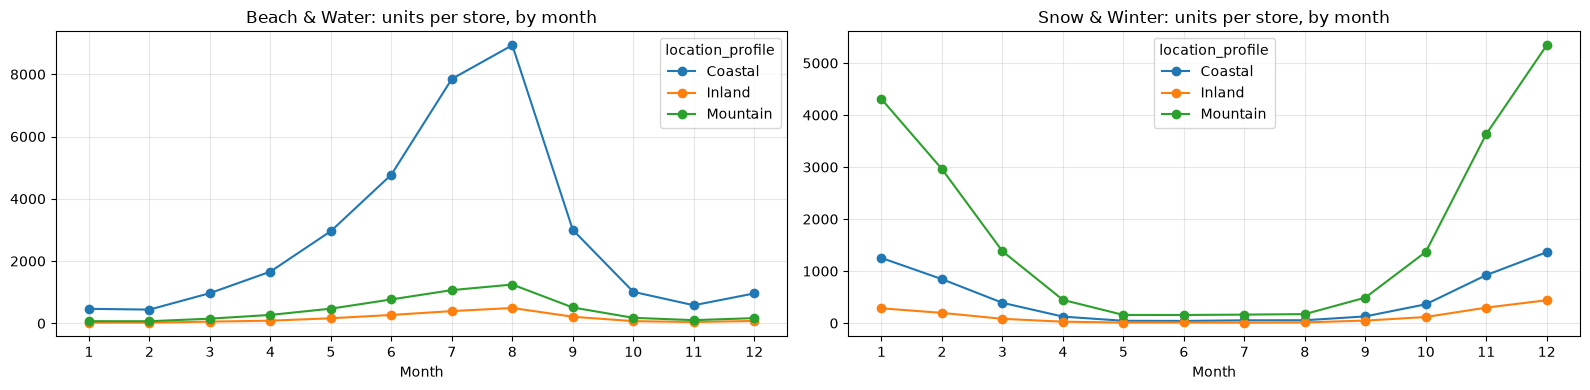

In [6]:
stores_per_profile = dim_store["location_profile"].value_counts()

fig, axes = plt.subplots(1, 2, figsize=(16, 4))
for ax, category in zip(axes, ["Beach & Water", "Snow & Winter"]):
    data = (sales[sales["category"] == category]
            .groupby([sales["date"].dt.month, "location_profile"])["quantity"].sum()
            .unstack())
    (data / stores_per_profile).plot(ax=ax, marker="o")
    ax.set_title(f"{category}: units per store, by month")
    ax.set_xticks(range(1, 13))
    ax.set_xlabel("Month")
    ax.grid(alpha=0.3)
plt.tight_layout()

## 5. Black Friday and Christmas
**Expected:** a clear peak on Black Friday, a high weekend after it, high sales in December until the 23rd, and no sales on 25 December.

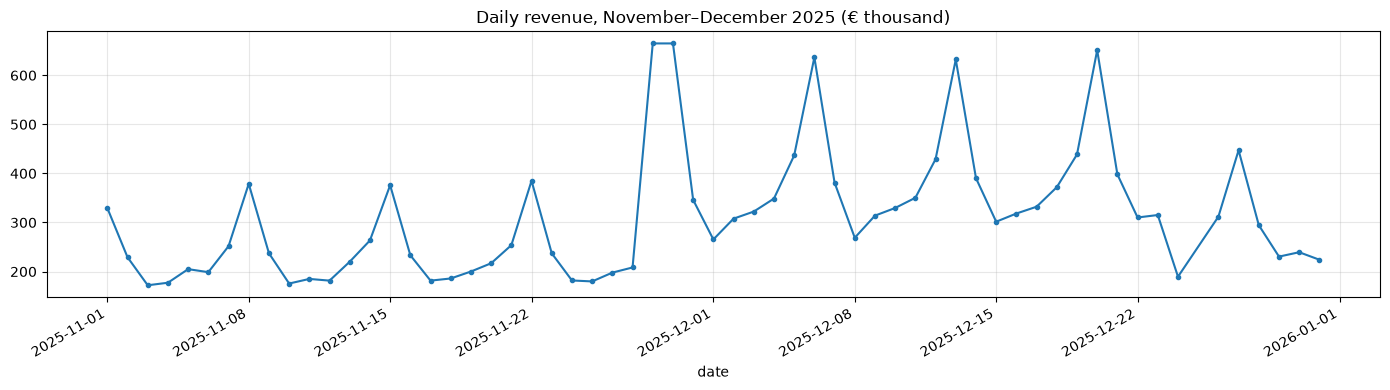

In [7]:
last_year = dim_date["year"].max()
period = sales[(sales["date"] >= f"{last_year}-11-01") & (sales["date"] <= f"{last_year}-12-31")]
daily = period.groupby("date")["revenue"].sum()

ax = (daily / 1e3).plot(figsize=(14, 4), marker=".")
ax.set_title(f"Daily revenue, November–December {last_year} (€ thousand)")
ax.grid(alpha=0.3)
plt.tight_layout()

## 6. Effect of the promotions
**Expected:** units per day of the promoted categories during each promotion, compared with the 14 days before. The change mixes the promotion with the season and the special dates:
* **Black Friday** and **Back to sport** show large increases (promotion + Black Friday peak; promotion + September peak of Fitness);
* **January sales** and **Summer sales** show small increases, because the days before are high-season days (Christmas; peak of the beach season) and the season is falling during the promotion.

Query 3.4 of notebook 04 isolates the promotion effect better, by comparing days with and without promotion in the same months.

In [8]:
daily_units = sales.groupby(["date", "product_id"])["quantity"].sum()

rows = []
for promotion in dim_promotion.itertuples():
    products = dim_product.loc[dim_product["category"].isin([c.strip() for c in promotion.categories.split(",")]), "product_id"]
    during = daily_units.loc[promotion.start_date:promotion.end_date]
    before = daily_units.loc[promotion.start_date - pd.Timedelta(days=14):promotion.start_date - pd.Timedelta(days=1)]
    during = during[during.index.get_level_values("product_id").isin(products)]
    before = before[before.index.get_level_values("product_id").isin(products)]
    days_during = (promotion.end_date - promotion.start_date).days + 1
    if len(before) > 0:
        rows.append({
            "promotion": promotion.promotion_name,
            "year": promotion.start_date.year,
            "units_per_day_before": before.sum() / 14,
            "units_per_day_during": during.sum() / days_during,
        })

promo_effect = pd.DataFrame(rows)
promo_effect["change_%"] = (100 * (promo_effect["units_per_day_during"] / promo_effect["units_per_day_before"] - 1)).round(1)
promo_effect.groupby("promotion")[["change_%"]].mean().round(1)

,change_%
promotion,
Back to sport,82.2
Black Friday,152.1
January sales,13.2
Spring cycling,58.4
Summer sales,6.1


## 7. New products and discontinued product
**Expected:** the e-bike, the paddle board and the GPS watch only sell after their launch and grow; the basic fitness tracker stops in June 2023.

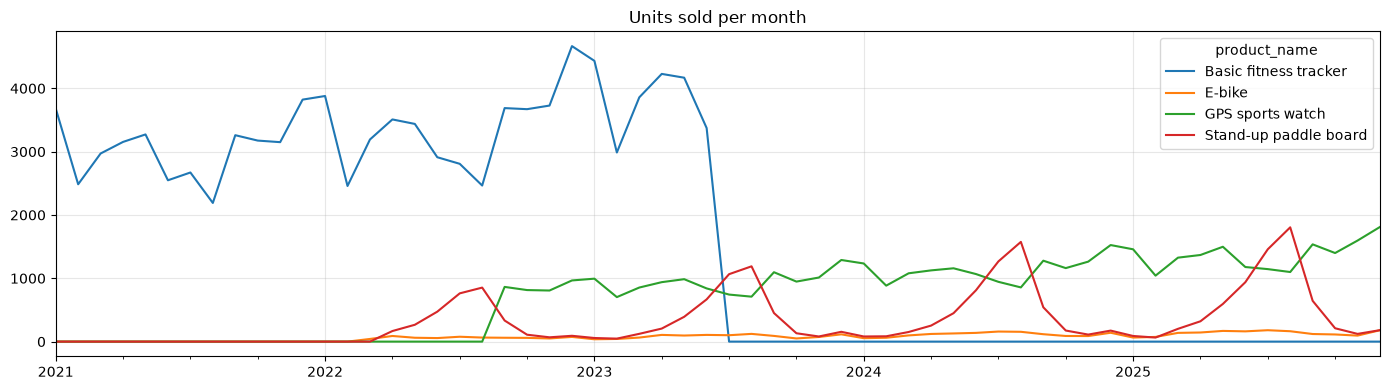

In [9]:
story_products = ["E-bike", "Stand-up paddle board", "GPS sports watch", "Basic fitness tracker"]
data = (sales[sales["product_name"].isin(story_products)]
        .groupby(["month", "product_name"])["quantity"].sum().unstack(fill_value=0))

ax = data.plot(figsize=(14, 4))
ax.set_title("Units sold per month")
ax.grid(alpha=0.3)
ax.set_xlabel("")
plt.tight_layout()

## 8. Ramp-up of new stores
**Expected:** a store that opens during the period starts at about 60% of its normal sales and reaches 100% after about six months (the season also moves the line).

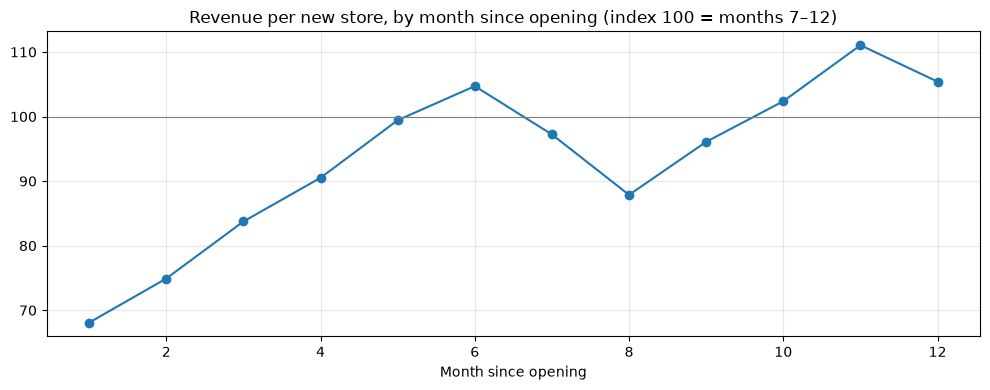

In [10]:
new_stores = dim_store[dim_store["opening_date"] >= START_DATE]

first_months = (
    sales[sales["store_id"].isin(new_stores["store_id"])]
    .merge(new_stores[["store_id", "opening_date"]], on="store_id")
)
first_months["month_since_opening"] = ((first_months["date"] - first_months["opening_date"]).dt.days // 30) + 1
first_months = first_months[first_months["month_since_opening"] <= 12]

curve = first_months.groupby("month_since_opening")["revenue"].sum() / first_months.groupby("month_since_opening")["store_id"].nunique()
ax = (100 * curve / curve.loc[7:12].mean()).plot(marker="o", figsize=(10, 4))
ax.axhline(100, color="grey", linewidth=0.8)
ax.set_title("Revenue per new store, by month since opening (index 100 = months 7–12)")
ax.set_xlabel("Month since opening")
ax.grid(alpha=0.3)
plt.tight_layout()

## 9. Store locations
**Expected:** stores concentrated in the most populated areas, with a few in mountain regions; the size of each point is the total revenue.

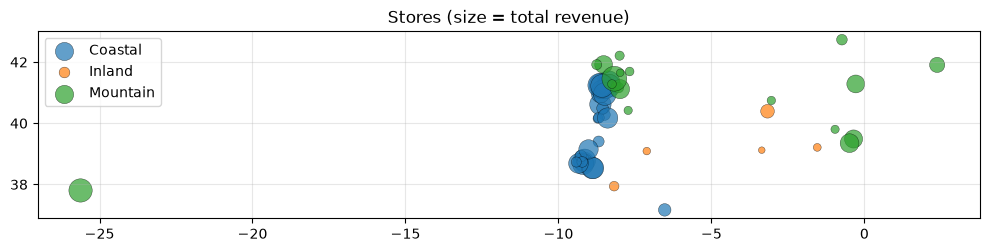

In [11]:
store_revenue = sales.groupby("store_id")["revenue"].sum()
stores_map = dim_store.set_index("store_id").join(store_revenue)
colors = {"Coastal": "tab:blue", "Inland": "tab:orange", "Mountain": "tab:green"}

fig, ax = plt.subplots(figsize=(10, 8))
for profile, group in stores_map.groupby("location_profile"):
    ax.scatter(group["lon"], group["lat"], s=20 + 300 * group["revenue"] / stores_map["revenue"].max(),
               c=colors[profile], alpha=0.7, label=profile, edgecolor="black", linewidth=0.3)
ax.set_title("Stores (size = total revenue)")
ax.legend()
ax.set_aspect("equal")
ax.grid(alpha=0.3)
plt.tight_layout()

## Summary
Every pattern built into the model can be seen in the data: growth and expansion to Spain, seasonality by category, weekday profile and opening rules, geography, special dates, promotions, product launches and store ramp-up. The data is ready for analysis in Power BI and SQL.